# Statistical Validation of Key Modeling Insights

This notebook complements the descriptive modeling findings with statistical
tests where they add evidence. It focuses on two questions that emerged during
the modeling phase:

1. Is Customer C46's order-level freight rate measurably different from the
   rest of the network?
2. Is plant-level capacity utilization associated with the other customer-level
   KPI components?

These tests address **data-level relationships**. Model robustness is assessed
separately through a **KPI-weight sensitivity analysis** once the Tableau
weighting parameters are implemented.

The workflow follows the common structure:
**explore → check assumptions → state hypotheses → test → interpret → document limitations**.


In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [2]:
from dotenv import dotenv_values

config = dotenv_values()
pg_user = config['POSTGRES_USER']
pg_pass = config['POSTGRES_PASS']
pg_host = config['POSTGRES_HOST']
pg_port = config['POSTGRES_PORT']
pg_db   = config['POSTGRES_DB']
pg_schema = config['POSTGRES_SCHEMA']

url = f'postgresql://{pg_user}:{pg_pass}@{pg_host}:{pg_port}/{pg_db}'
engine = create_engine(url, connect_args={"options": f"-csearch_path={pg_schema}"})

---
### 1. C46 Freight Rate: Group Difference

### Business question

Is C46's average order-level freight rate different from the freight rate of
all other orders in the network?

- **H₀:** μ(C46 orders) = μ(other orders)
- **H₁:** μ(C46 orders) ≠ μ(other orders)

The test is two-sided. Earlier diagnostics already showed the direction of the
difference; keeping the inferential test two-sided avoids tailoring the
hypothesis to an already observed result.

### Unit of analysis

The comparison is performed at **order level** because the underlying finding
concerns the freight-rate structure across C46's orders. This provides two
samples: C46 orders and all other orders.

**Important limitation:** orders within the same customer or lane may share
common pricing structures and therefore are not guaranteed to be fully
independent observations. The test is used as supporting evidence, not as a
causal claim.


In [3]:
orders = pd.read_sql("""
    select customer, avg_rate
    from prep_order_freight
""", engine)

c46_orders = (
    orders.loc[orders["customer"] == "V555555_6", "avg_rate"]
    .dropna()
)

other_orders = (
    orders.loc[orders["customer"] != "V555555_6", "avg_rate"]
    .dropna()
)

summary_c46 = pd.DataFrame({
    "group": ["C46", "Other orders"],
    "n": [len(c46_orders), len(other_orders)],
    "mean_rate": [c46_orders.mean(), other_orders.mean()],
    "median_rate": [c46_orders.median(), other_orders.median()],
    "std_rate": [c46_orders.std(), other_orders.std()]
})

summary_c46


,group,n,mean_rate,median_rate,std_rate
0,C46,761,0.5626,0.0484,2.4562
1,Other orders,6234,0.0895,0.0484,0.2436


### Distribution check

The earlier SQL diagnostics indicated that C46 contains two distinct rate
patterns: a large group of orders at the regular rate and a small group on one
lane at a much higher rate. The plots below make that structure visible.

A formal normality test is **not used as a decision criterion** here: the
non-normal / bimodal structure is already evident from the diagnostic
distribution, and large samples can make normality tests reject even small
departures from normality.


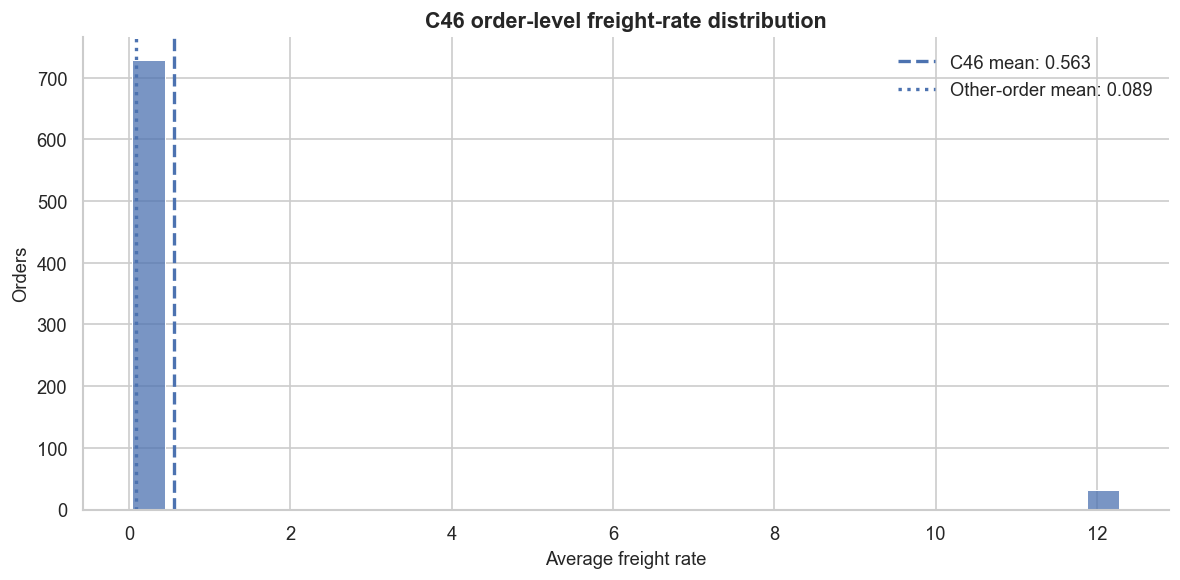

In [4]:
# Presentation-friendly plotting defaults
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 120
})

fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    c46_orders,
    bins=30,
    stat="count",
    edgecolor="white",
    linewidth=0.6,
    ax=ax
)

ax.axvline(
    c46_orders.mean(),
    linestyle="--",
    linewidth=2,
    label=f"C46 mean: {c46_orders.mean():.3f}"
)
ax.axvline(
    other_orders.mean(),
    linestyle=":",
    linewidth=2,
    label=f"Other-order mean: {other_orders.mean():.3f}"
)

ax.set_title("C46 order-level freight-rate distribution")
ax.set_xlabel("Average freight rate")
ax.set_ylabel("Orders")
ax.legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.show()


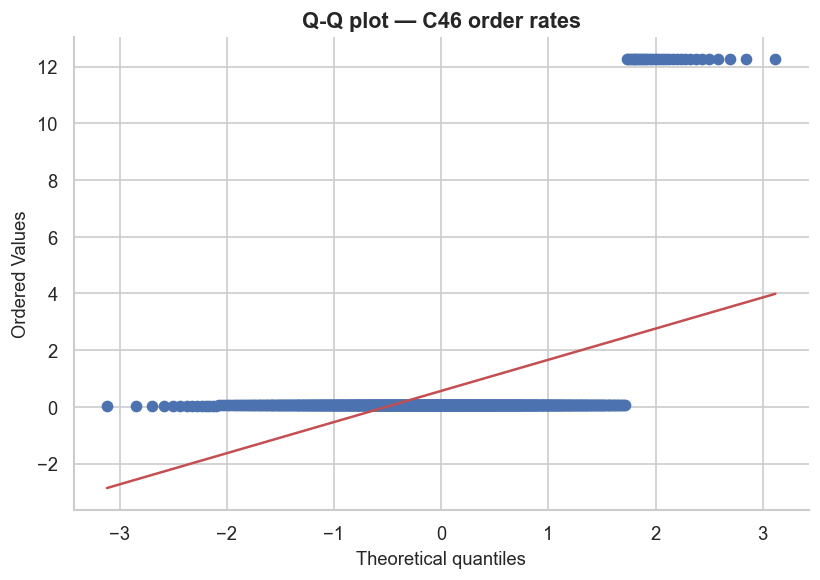

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
stats.probplot(c46_orders, dist="norm", plot=ax)
ax.set_title("Q-Q plot — C46 order rates")
sns.despine()
plt.tight_layout()
plt.show()


### Statistical test — Welch two-sample t-test

The comparison mean for the rest of the network is itself estimated from data,
so the appropriate comparison is a **two-sample test**, not a one-sample test.
Welch's t-test is used because it does not assume equal variances between C46
and the remaining orders.

With large samples, inference on the difference in means is generally robust
to non-normal observations, although the dependence limitation noted above
still applies.


In [6]:
t_stat, p_value = stats.ttest_ind(
    c46_orders,
    other_orders,
    equal_var=False
)

alpha = 0.05

print(f"Welch t-statistic: {t_stat:.2f}")
print(f"p-value: {p_value:.10g}")

if p_value < alpha:
    print("Reject H0: the mean freight rate differs between C46 and the other orders.")
else:
    print("Fail to reject H0: no statistically detectable mean difference.")


Welch t-statistic: 5.31
p-value: 1.440613377e-07
Reject H0: the mean freight rate differs between C46 and the other orders.


In [7]:
# 95% confidence interval for the difference in means: C46 - other orders
mean_diff = c46_orders.mean() - other_orders.mean()

se_diff = np.sqrt(
    c46_orders.var(ddof=1) / len(c46_orders)
    + other_orders.var(ddof=1) / len(other_orders)
)

df_welch = (
    (c46_orders.var(ddof=1) / len(c46_orders)
     + other_orders.var(ddof=1) / len(other_orders)) ** 2
    /
    (
        (c46_orders.var(ddof=1) / len(c46_orders)) ** 2 / (len(c46_orders) - 1)
        + (other_orders.var(ddof=1) / len(other_orders)) ** 2 / (len(other_orders) - 1)
    )
)

critical_t = stats.t.ppf(0.975, df_welch)
ci_low = mean_diff - critical_t * se_diff
ci_high = mean_diff + critical_t * se_diff

print(f"Mean difference (C46 - others): {mean_diff:.4f}")
print(f"95% CI for mean difference: [{ci_low:.4f}, {ci_high:.4f}]")


Mean difference (C46 - others): 0.4731
95% CI for mean difference: [0.2982, 0.6480]


### Interpretation

If the confidence interval excludes zero and the Welch test rejects H₀, the
data provide statistical evidence that C46's mean order-level freight rate
differs from the rest of the network.

This supports the earlier diagnostic finding that C46 is not merely visually
unusual in Tableau. It **does not establish why** the rate differs and does
not prove that the source value is economically correct. The handling/storage
fee explanation therefore remains a working theory rather than a confirmed
finding.


---
### 2. Capacity Concentration: Structural Evidence

The primary evidence for the capacity finding is **structural and
descriptive**: 26 of 46 customers share the same capacity-utilization value.
That directly limits the KPI's ability to differentiate customers within that
group.

The following check quantifies that concentration before any cross-KPI
association is tested.


In [8]:
kpi_base = pd.read_sql(
    """
    select
        avg_capacity_utilization,
        pct_late,
        weighted_avg_rate
    from prep_customer_kpi_base
    """,
    engine
).dropna()


In [9]:
capacity_counts = (
    kpi_base["avg_capacity_utilization"]
    .value_counts(dropna=False)
    .rename_axis("avg_capacity_utilization")
    .reset_index(name="n_customers")
)

capacity_counts["share_of_customers"] = (
    capacity_counts["n_customers"] / len(kpi_base)
)

capacity_counts.head(10)


,avg_capacity_utilization,n_customers,share_of_customers
0,8.4294,22,0.5500
1,1.4354,3,0.0750
2,8.3485,1,0.0250
3,7.9018,1,0.0250
4,8.1785,1,0.0250
5,8.3595,1,0.0250
6,8.2471,1,0.0250
7,8.3749,1,0.0250
8,8.4101,1,0.0250
9,6.9105,1,0.0250


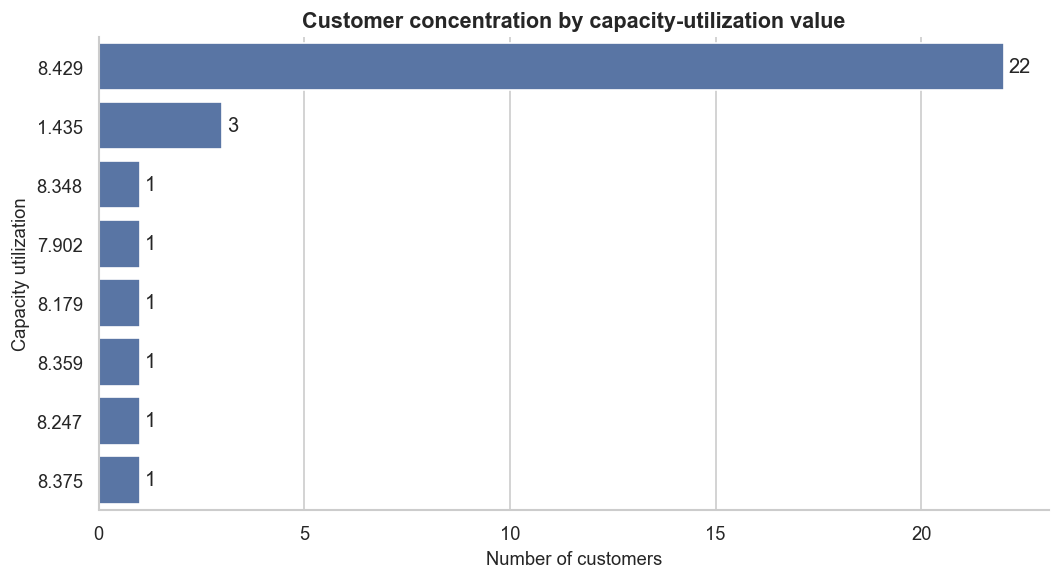

In [10]:
top_capacity = capacity_counts.head(8).copy()
top_capacity["capacity_label"] = top_capacity["avg_capacity_utilization"].map(
    lambda x: f"{x:.3f}"
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=top_capacity,
    x="n_customers",
    y="capacity_label",
    ax=ax
)

ax.set_title("Customer concentration by capacity-utilization value")
ax.set_xlabel("Number of customers")
ax.set_ylabel("Capacity utilization")

for container in ax.containers:
    ax.bar_label(container, padding=3)

sns.despine()
plt.tight_layout()
plt.show()


### Interpretation

A large customer cluster sharing an identical utilization value is direct
evidence that the capacity KPI contains a strong shared structural component.
This is the basis for the Insight 1 limitation: the KPI can represent network
concentration while offering limited customer-level differentiation inside
that cluster.


---
### 3. Exploratory Cross-KPI Association

### Business question

Is plant-level capacity utilization associated with customer-level delivery
lateness or freight rate?

This is a **secondary, exploratory question**. It does not prove or disprove
the structural concentration finding above.

For each KPI pair:

- **H₀:** ρ = 0 — no monotonic association
- **H₁:** ρ ≠ 0 — a monotonic association exists

**Spearman correlation** is the primary measure because capacity utilization
contains many tied values and the KPI distributions are non-normal. Pearson
is retained only as a reference for linear association.


In [11]:
results = []

for col in ["pct_late", "weighted_avg_rate"]:
    r_spearman, p_spearman = stats.spearmanr(
        kpi_base["avg_capacity_utilization"],
        kpi_base[col]
    )
    r_pearson, p_pearson = stats.pearsonr(
        kpi_base["avg_capacity_utilization"],
        kpi_base[col]
    )

    results.append({
        "kpi": col,
        "spearman_rho": r_spearman,
        "spearman_p": p_spearman,
        "pearson_r": r_pearson,
        "pearson_p": p_pearson
    })

correlation_results = pd.DataFrame(results)
correlation_results


,kpi,spearman_rho,spearman_p,pearson_r,pearson_p
0,pct_late,0.1367,0.4001,0.0647,0.6917
1,weighted_avg_rate,0.0209,0.8979,0.0505,0.7572


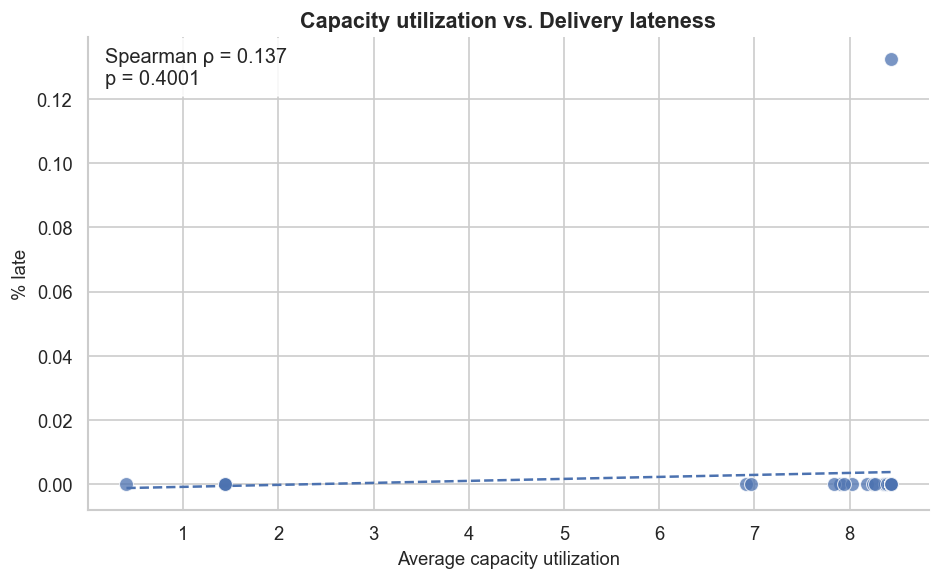

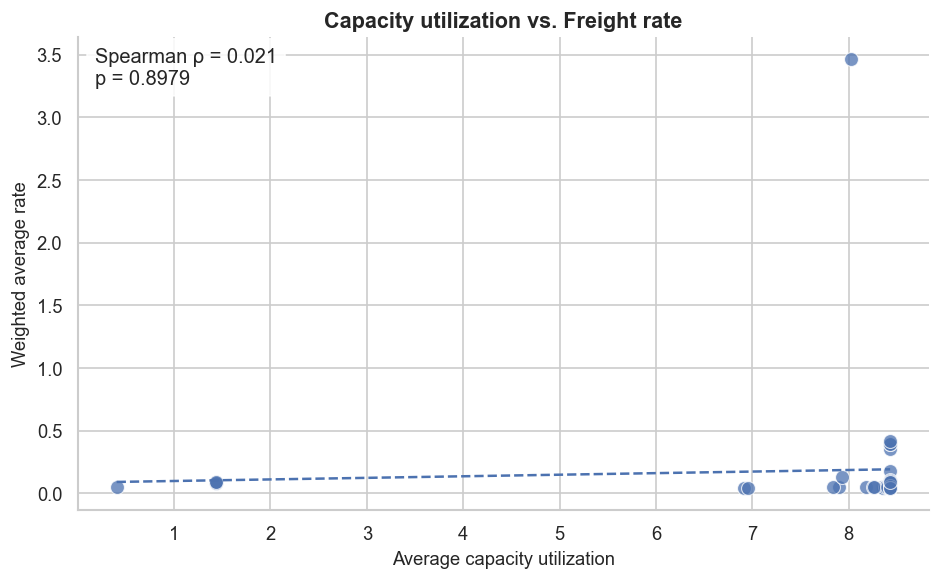

In [12]:
plot_specs = [
    ("pct_late", "Delivery lateness", "% late"),
    ("weighted_avg_rate", "Freight rate", "Weighted average rate")
]

for col, title, y_label in plot_specs:
    fig, ax = plt.subplots(figsize=(8, 5))

    sns.scatterplot(
        data=kpi_base,
        x="avg_capacity_utilization",
        y=col,
        s=70,
        alpha=0.75,
        ax=ax
    )

    sns.regplot(
        data=kpi_base,
        x="avg_capacity_utilization",
        y=col,
        scatter=False,
        ci=None,
        line_kws={"linestyle": "--", "linewidth": 1.5},
        ax=ax
    )

    rho, p = stats.spearmanr(
        kpi_base["avg_capacity_utilization"],
        kpi_base[col]
    )

    ax.set_title(f"Capacity utilization vs. {title}")
    ax.set_xlabel("Average capacity utilization")
    ax.set_ylabel(y_label)
    ax.text(
        0.02, 0.98,
        f"Spearman ρ = {rho:.3f}\np = {p:.4f}",
        transform=ax.transAxes,
        va="top",
        bbox={"boxstyle": "round,pad=0.4", "facecolor": "white", "alpha": 0.85}
    )

    sns.despine()
    plt.tight_layout()
    plt.show()


### Interpretation

The Spearman results should be interpreted as evidence about **association**,
not independence.

- A non-significant result means that no monotonic association was detected
  in this sample.
- A significant result indicates an association worth investigating further;
  it does not establish causality.
- With only 46 customers and 26 customers sharing one capacity value, the
  effective differentiation and statistical power are limited.

The cross-KPI analysis therefore complements the structural concentration
finding but is not used as proof that capacity is plant-driven.


---
### 4. Methods Considered but Not Used

| Method | Why it is not part of the main evidence |
|---|---|
| Shapiro-Wilk / Anderson-Darling / KS | Distribution shape is already established diagnostically; formal normality testing adds little decision value here. |
| One-sample t-test for C46 | The network reference mean is estimated from the comparison data; Welch's two-sample test matches the actual two-group comparison. |
| OLS regression | Prediction / explanatory modeling is not the research question for the cross-KPI check. |
| Pearson as primary correlation | Capacity contains substantial ties and non-normal structure; Spearman is more appropriate as the primary association measure. |
| KPI-weight sensitivity analysis | This addresses robustness of the APIndex model, not statistical relationships in the source data; it is performed separately after the Tableau weighting implementation. |


---
## Conclusion and Link to Model Validation

This notebook adds inferential support where it is useful without treating
statistical significance as proof of the business explanation.

- **C46:** Welch's two-sample test evaluates whether its mean order-level
  freight rate differs from the remaining network orders.
- **Capacity concentration:** the 26/46 cluster is the primary structural
  evidence for limited customer-level differentiation.
- **Cross-KPI association:** Spearman correlation is exploratory and tests
  whether capacity utilization is monotonically associated with delivery
  lateness or freight rate.
- **Next validation layer:** KPI-weight sensitivity analysis tests whether
  APIndex prioritization remains robust under different stakeholder weighting
  profiles.

Together, the statistical checks and the later sensitivity analysis address
two different validation layers: **data-level evidence** and **model-level
robustness**.
